In [31]:
import pandas as pd
df = pd.read_excel('mymoviedb_cleaned.xlsx')

In [32]:
df.head()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original Language,Genre
0,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.95,8940,8.3,English,Action
1,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.95,8940,8.3,English,Adventure
2,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.95,8940,8.3,English,Science Fiction
3,2022-03-01,The Batman,"In his second year of fighting crime, Batman u...",3827.66,1151,8.1,English,Crime
4,2022-03-01,The Batman,"In his second year of fighting crime, Batman u...",3827.66,1151,8.1,English,Mystery


In [33]:
df.tail()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original Language,Genre
25787,2021-03-31,The United States vs. Billie Holiday,Billie Holiday spent much of her career being ...,13.35,152,6.7,English,Drama
25788,2021-03-31,The United States vs. Billie Holiday,Billie Holiday spent much of her career being ...,13.35,152,6.7,English,History
25789,1984-09-23,Threads,Documentary style account of a nuclear holocau...,13.35,186,7.8,English,War
25790,1984-09-23,Threads,Documentary style account of a nuclear holocau...,13.35,186,7.8,English,Drama
25791,1984-09-23,Threads,Documentary style account of a nuclear holocau...,13.35,186,7.8,English,Science Fiction


In [34]:
df.shape

(25792, 8)

In [35]:
df.describe()

,Release_Date,Popularity,Vote_Count,Vote_Average
count,25792,25792.000000,25792.000000,25792.000000
mean,2006-07-17 17:34:02.307692544,42.000987,1504.881514,6.475725
min,1902-04-17 00:00:00,13.350000,0.000000,0.000000
25%,2000-09-01 00:00:00,16.370000,166.000000,6.000000
50%,2011-01-28 00:00:00,21.865000,490.000000,6.600000
75%,2017-08-30 00:00:00,36.500000,1501.000000,7.200000
max,2024-07-03 00:00:00,5083.950000,31077.000000,10.000000
std,NaN,113.343126,2743.047498,1.091310


In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25792 entries, 0 to 25791
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Release_Date       25792 non-null  datetime64[ns]
 1   Title              25792 non-null  object        
 2   Overview           25792 non-null  object        
 3   Popularity         25792 non-null  float64       
 4   Vote_Count         25792 non-null  int64         
 5   Vote_Average       25792 non-null  float64       
 6   Original Language  25792 non-null  object        
 7   Genre              25792 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 1.6+ MB


## Extra Tables for Further Use

In [61]:
movie_genres = pd.DataFrame({
    "Title": df["Title"],
    "Release_Date": df["Release_Date"],
    "Genre": df["Genre"]
})

movie_genres["Movie_Label"] = (
    movie_genres["Title"].astype(str)
    + "\n" + " (" 
    + movie_genres["Release_Date"].dt.strftime("%Y-%m-%d")
    + ")"
)

movie_data = df.drop_duplicates(
    subset=["Title", "Release_Date"]
).drop("Genre", axis=1)

movie_data["Movie_Label"] = (
    movie_data["Title"].astype(str)
    + "\n" + " (" 
    + movie_data["Release_Date"].dt.strftime("%Y-%m-%d")
    + ")"
)

## KPIs

In [62]:
total_movies = len(movie_data)
average_rating = movie_data["Vote_Average"].mean()
average_popularity = movie_data["Popularity"].mean()
total_votes = movie_data["Vote_Count"].sum()
total_languages = movie_data["Original Language"].nunique()
total_genres = df["Genre"].nunique()

In [63]:
print(f"Total Movies       : {total_movies:,}")
print(f"Average Rating     : {average_rating:.2f}")
print(f"Average Popularity : {average_popularity:.2f}")
print(f"Total Votes        : {total_votes:,}")
print(f"Total Languages    : {total_languages}")
print(f"Total Genres       : {total_genres}")

Total Movies       : 9,826
Average Rating     : 6.44
Average Popularity : 40.32
Total Votes        : 13,687,065
Total Languages    : 43
Total Genres       : 19


## Import for Graphs

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

## Total Movies Per Year

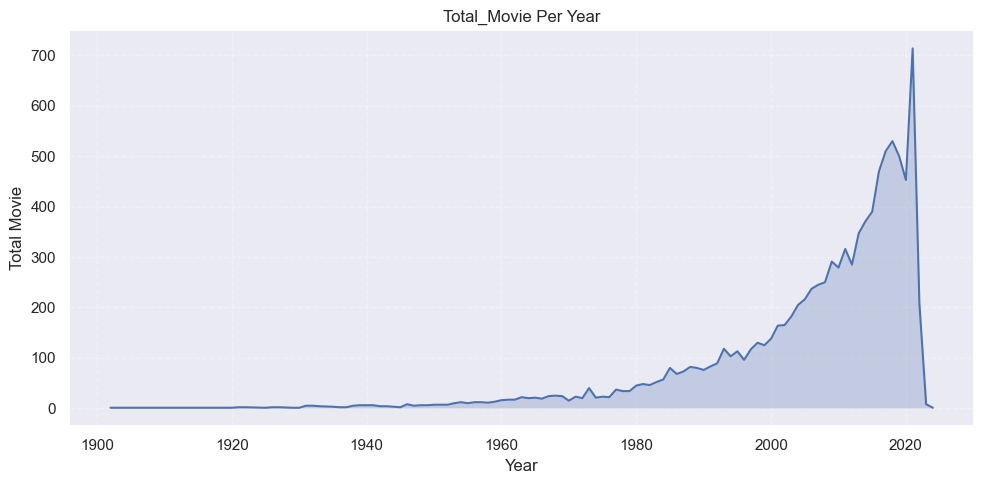

In [65]:
movies_per_year = (
    movie_data.groupby(movie_data["Release_Date"].dt.year)
    .size()
    .reset_index(name="Total_Movie")
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=movies_per_year,
    x="Release_Date",
    y="Total_Movie"
)

plt.fill_between(
    movies_per_year["Release_Date"],
    movies_per_year["Total_Movie"],
    alpha=0.25
)

plt.title("Total_Movie Per Year")
plt.xlabel("Year")
plt.ylabel("Total Movie")

plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## Top 10 Most Popular Movies

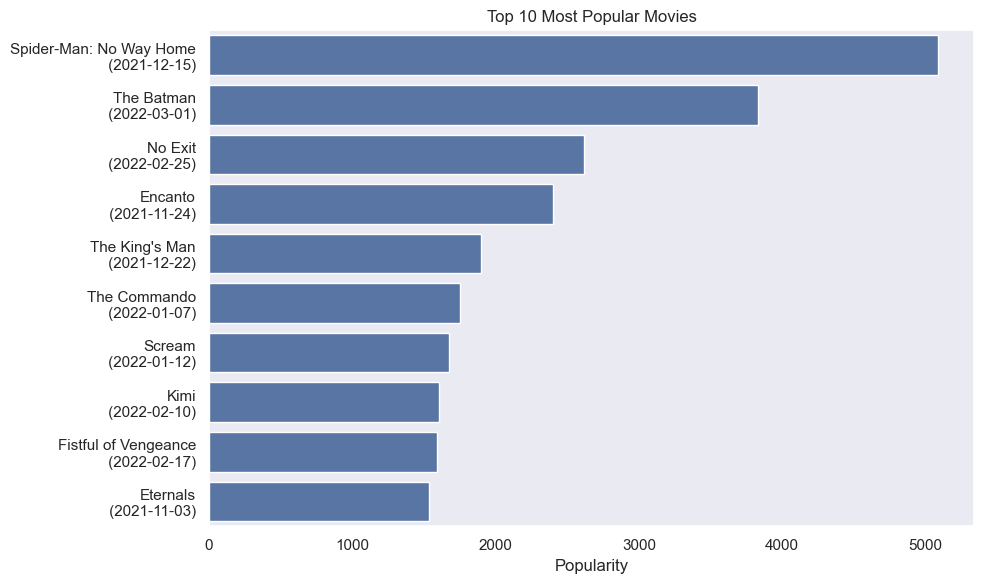

In [66]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=movie_data.sort_values(by="Popularity", ascending=False).head(10),
    x="Popularity",
    y="Movie_Label"
)

plt.title("Top 10 Most Popular Movies")
plt.xlabel("Popularity")
plt.ylabel("")

plt.tight_layout()
plt.show()

## Top 10 Genres

In [71]:
genre_count = (
    movie_genres.groupby("Genre")["Movie_Label"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Movie Count")
)

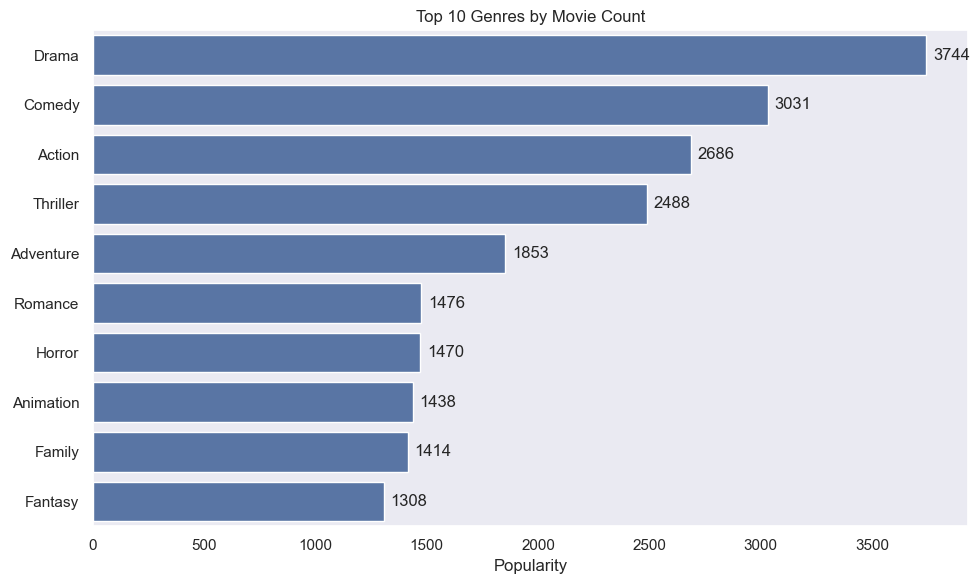

In [90]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data = genre_count,
    x="Movie Count",
    y="Genre"
)

for i, value in enumerate(genre_count["Movie Count"]):
    ax.text(
        value + 30,
        i,
        f"{value}",
        va="center"
    )

plt.title("Top 10 Genres by Movie Count")
plt.xlabel("Popularity")
plt.ylabel("")

plt.tight_layout()
plt.show()

## Top 10 Average Rating by Genre

In [79]:
genre_analysis = movie_genres.merge(
    movie_data[["Movie_Label", "Vote_Average"]],
    on="Movie_Label",
    how="left"
)

In [83]:
genre_rating = (
    genre_analysis.groupby("Genre")["Vote_Average"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=False)
    .reset_index(name="Average Rating")
)

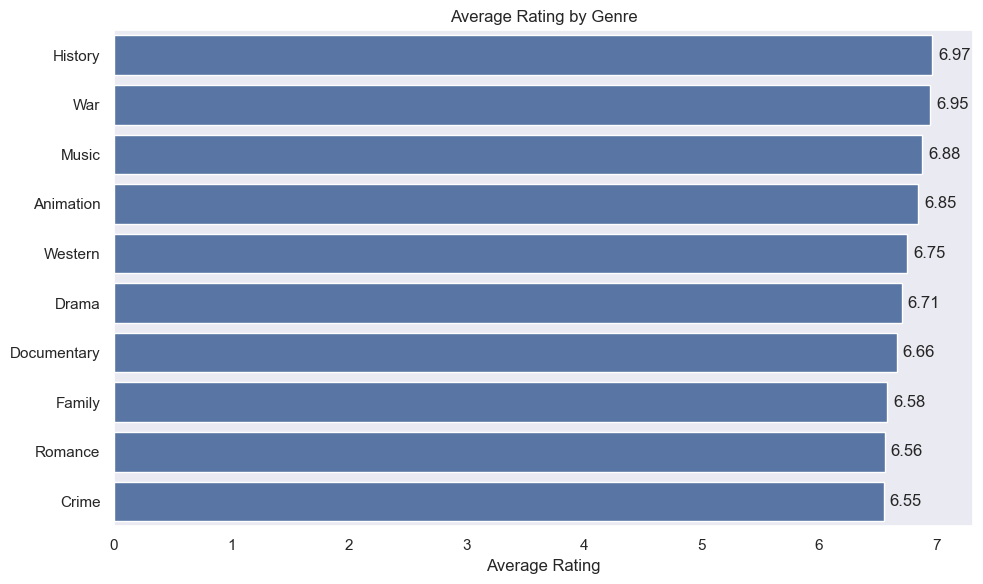

In [88]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=genre_rating,
    x="Average Rating",
    y="Genre"
)

for i, value in enumerate(genre_rating["Average Rating"]):
    ax.text(
        value + 0.05,
        i,
        f"{value:.2f}",
        va="center"
    )

plt.title("Average Rating by Genre")
plt.xlabel("Average Rating")
plt.ylabel("")

plt.tight_layout()
plt.show()

## Top 10 Languages By Movie Count

In [99]:
language_count = (
    movie_data.groupby("Original Language")["Movie_Label"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
    .reset_index(name="Total_Movie")
)

language_count["Original Language"] = language_count["Original Language"].replace(
    "Chinese (non-standard; usually Simplified Chinese in datasets)",
    "Chinese (non-standard)"
)

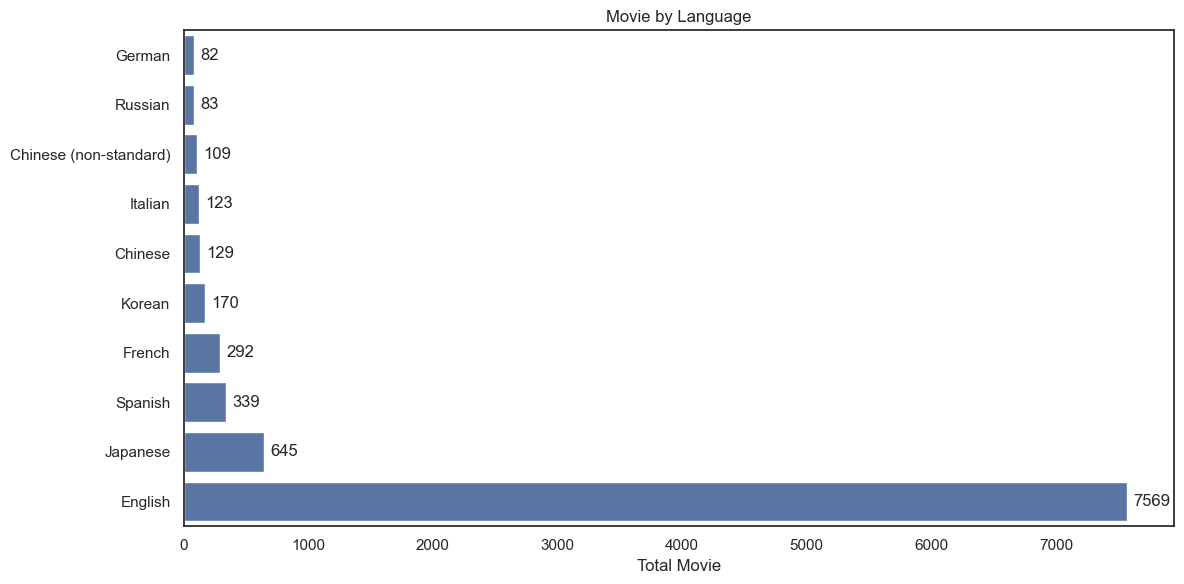

In [103]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=language_count,
    x="Total_Movie",
    y="Original Language"
)

for i, value in enumerate(language_count["Total_Movie"]):
    ax.text(
        value + 50,
        i,
        f"{value}",
        va="center"
    )

plt.title("Movie by Language")
plt.xlabel("Total Movie")
plt.ylabel("")

plt.tight_layout()
plt.show()